# Byproduct Selection
In this notebook, we select a set of high priority byproducts to focus on for this analysis.

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from cmcrameri import cm

from molmass import Formula

# add main repo directory to path
import sys
import os
sys.path.append(os.path.abspath('..'))

# add submodules to path
sys.path.append('../submodules/gw-avail-and-comp')

# set up figure style in same way as gw-avail-and-comp repo
from project_utils import setup_figure_style, subscript_numbers
setup_figure_style()

# Load Data

In [5]:
# load composition data
comp_path = '../submodules/gw-avail-and-comp/final_datasets/composition_summary_statistics.csv'
comp_df = pd.read_csv(comp_path)

# drop rows that aren't brackish groundwater (TDS < 1000 mg/L or TDS > 10000 mg/L)
comp_df = comp_df[(comp_df['TDS_mgL_mean'] >= 1000) & (comp_df['TDS_mgL_mean'] <= 10000)].copy()

# isolate mean concentration columns
conc_cols = [col for col in comp_df.columns if col.endswith('gL_mean') and col != 'TDS_mgL_mean']
comp_df = comp_df[conc_cols].copy()

# convert all units to mg/L
for col in comp_df.columns:
    if col.endswith('ugL_mean'):
        comp_df[col] = comp_df[col] / 1000
        comp_df.rename(columns={col: col.replace('ugL', 'mgL')}, inplace=True)

# Identify High Concentration Species

In [6]:
# identify species with a sufficiently high median concentration
conc_threshold = 0.1 # mg/L
print(f'Species with median concentration above threshold ({conc_threshold} mg/L):')
cols_above_threshold = []
for col in comp_df.columns:
    if comp_df[col].median() >= conc_threshold: # mg/L
        print(f'\t{col.split("_")[0]}: {comp_df[col].median():.2f} mg/L')
        cols_above_threshold.append(col)
species_above_threshold = [col.split('_')[0] for col in cols_above_threshold]

Species with median concentration above threshold (0.1 mg/L):
	B: 1.29 mg/L
	Ba: 0.12 mg/L
	Br: 0.97 mg/L
	CO3: 4.36 mg/L
	Ca: 116.51 mg/L
	Cl: 448.72 mg/L
	F: 1.50 mg/L
	Fe: 0.93 mg/L
	HCO3: 321.04 mg/L
	K: 10.03 mg/L
	Li: 0.12 mg/L
	Mg: 45.07 mg/L
	NH4: 0.63 mg/L
	NO3: 2.71 mg/L
	Na: 626.73 mg/L
	PO4: 0.12 mg/L
	SO4: 415.87 mg/L
	SiO2: 13.81 mg/L
	Sr: 2.25 mg/L


# Visualization

In [7]:
# assign each species to cation or anion side based on how it contributes to compounds
species_type_dict = {
    'Ag': 'cation', 
    'Al': 'cation', 
    'As': 'anion', 
    'B': 'anion',   # borate
    'Ba': 'cation',
    'Be': 'cation', 
    'Br': 'anion', 
    'Ca': 'cation', 
    'Cd': 'cation', 
    'Cl': 'anion',
    'Co': 'cation',
    'CO3': 'anion', 
    'Cr': 'cation', 
    'Cu': 'cation', 
    'F': 'anion', 
    'Fe': 'cation',
    'HCO3': 'anion', 
    'K': 'cation', 
    'Li': 'cation', 
    'Mg': 'cation', 
    'Mn': 'cation',
    'Mo': 'anion', 
    'NH4': 'cation', 
    'NO2': 'anion', 
    'NO3': 'anion', 
    'Na': 'cation',
    'Ni': 'cation', 
    'PO4': 'anion', 
    'Pb': 'cation', 
    'SO4': 'anion', 
    'Sb': 'anion', # antimonate
    'Se': 'anion', 
    'SiO2': 'anion', # silicates
    'Sr': 'cation', 
    'Tl': 'cation', 
    'V': 'anion',
    'Zn': 'cation'
}
type_to_species_dict = {}
for species, species_type in species_type_dict.items():
    type_to_species_dict[species_type] = type_to_species_dict.get(species_type, []) + [species]

# create a color dictionary for each species based on the gates it clears
species_color_dict = dict.fromkeys(species_type_dict.keys(), 'whitesmoke') # default
# for col in cols_above_threshold:
#     species = col.split('_')[0]
#     species_color_dict[species] = 'lightgrey' # dark grey for species that clear the concentration threshold
ion_cmap_dict = {
    'cation' : cm.lajolla_r,
    'anion' : cm.navia_r,
}
for ion_type in ('cation', 'anion'):
    species_list = type_to_species_dict[ion_type]
    cmap = ion_cmap_dict[ion_type]
    n_species = len(species_list)
    colors = [cmap(v) for v in np.linspace(0.15, 0.85, n_species)]
    for species, color in zip(species_list, colors):
        species_color_dict[species] = color

In [11]:
# assign each species to cation or anion side based on how it contributes to compounds
species_type_dict = {
    'Ag': 'cation', 
    'Al': 'cation', 
    'As': 'anion', 
    'B': 'anion',   # borate
    'Ba': 'cation',
    'Be': 'cation', 
    'Br': 'anion', 
    'Ca': 'cation', 
    'Cd': 'cation', 
    'Cl': 'anion',
    'Co': 'cation',
    'CO3': 'anion', 
    'Cr': 'cation', 
    'Cu': 'cation', 
    'F': 'anion', 
    'Fe': 'cation',
    'HCO3': 'anion', 
    'K': 'cation', 
    'Li': 'cation', 
    'Mg': 'cation', 
    'Mn': 'cation',
    'Mo': 'anion', 
    'NH4': 'cation', 
    'NO2': 'anion', 
    'NO3': 'anion', 
    'Na': 'cation',
    'Ni': 'cation', 
    'PO4': 'anion', 
    'Pb': 'cation', 
    'SO4': 'anion', 
    'Sb': 'anion', # antimonate
    'Se': 'anion', 
    'SiO2': 'anion', # silicates
    'Sr': 'cation', 
    'Tl': 'cation', 
    'V': 'anion',
    'Zn': 'cation'
}
type_to_species_dict = {}
for species, species_type in species_type_dict.items():
    type_to_species_dict[species_type] = type_to_species_dict.get(species_type, []) + [species]

# create a color dictionary for each species based on the gates it clears
species_color_dict = dict.fromkeys(species_type_dict.keys(), 'whitesmoke') # default
# for col in cols_above_threshold:
#     species = col.split('_')[0]
#     species_color_dict[species] = 'lightgrey' # dark grey for species that clear the concentration threshold
ion_cmap_dict = {
    'cation' : cm.lajolla_r,
    'anion' : cm.navia_r,
}
for ion_type in ('cation', 'anion'):
    species_list = sorted(
        set(type_to_species_dict[ion_type]).intersection(set(species_above_threshold)),
        key=str.lower
    )
    cmap = ion_cmap_dict[ion_type]
    n_species = len(species_list)
    colors = [cmap(v) for v in np.linspace(0.15, 0.85, n_species)]
    for species, color in zip(species_list, colors):
        species_color_dict[species] = color

Text(0.5, 0, 'Concentration (mg/L)')

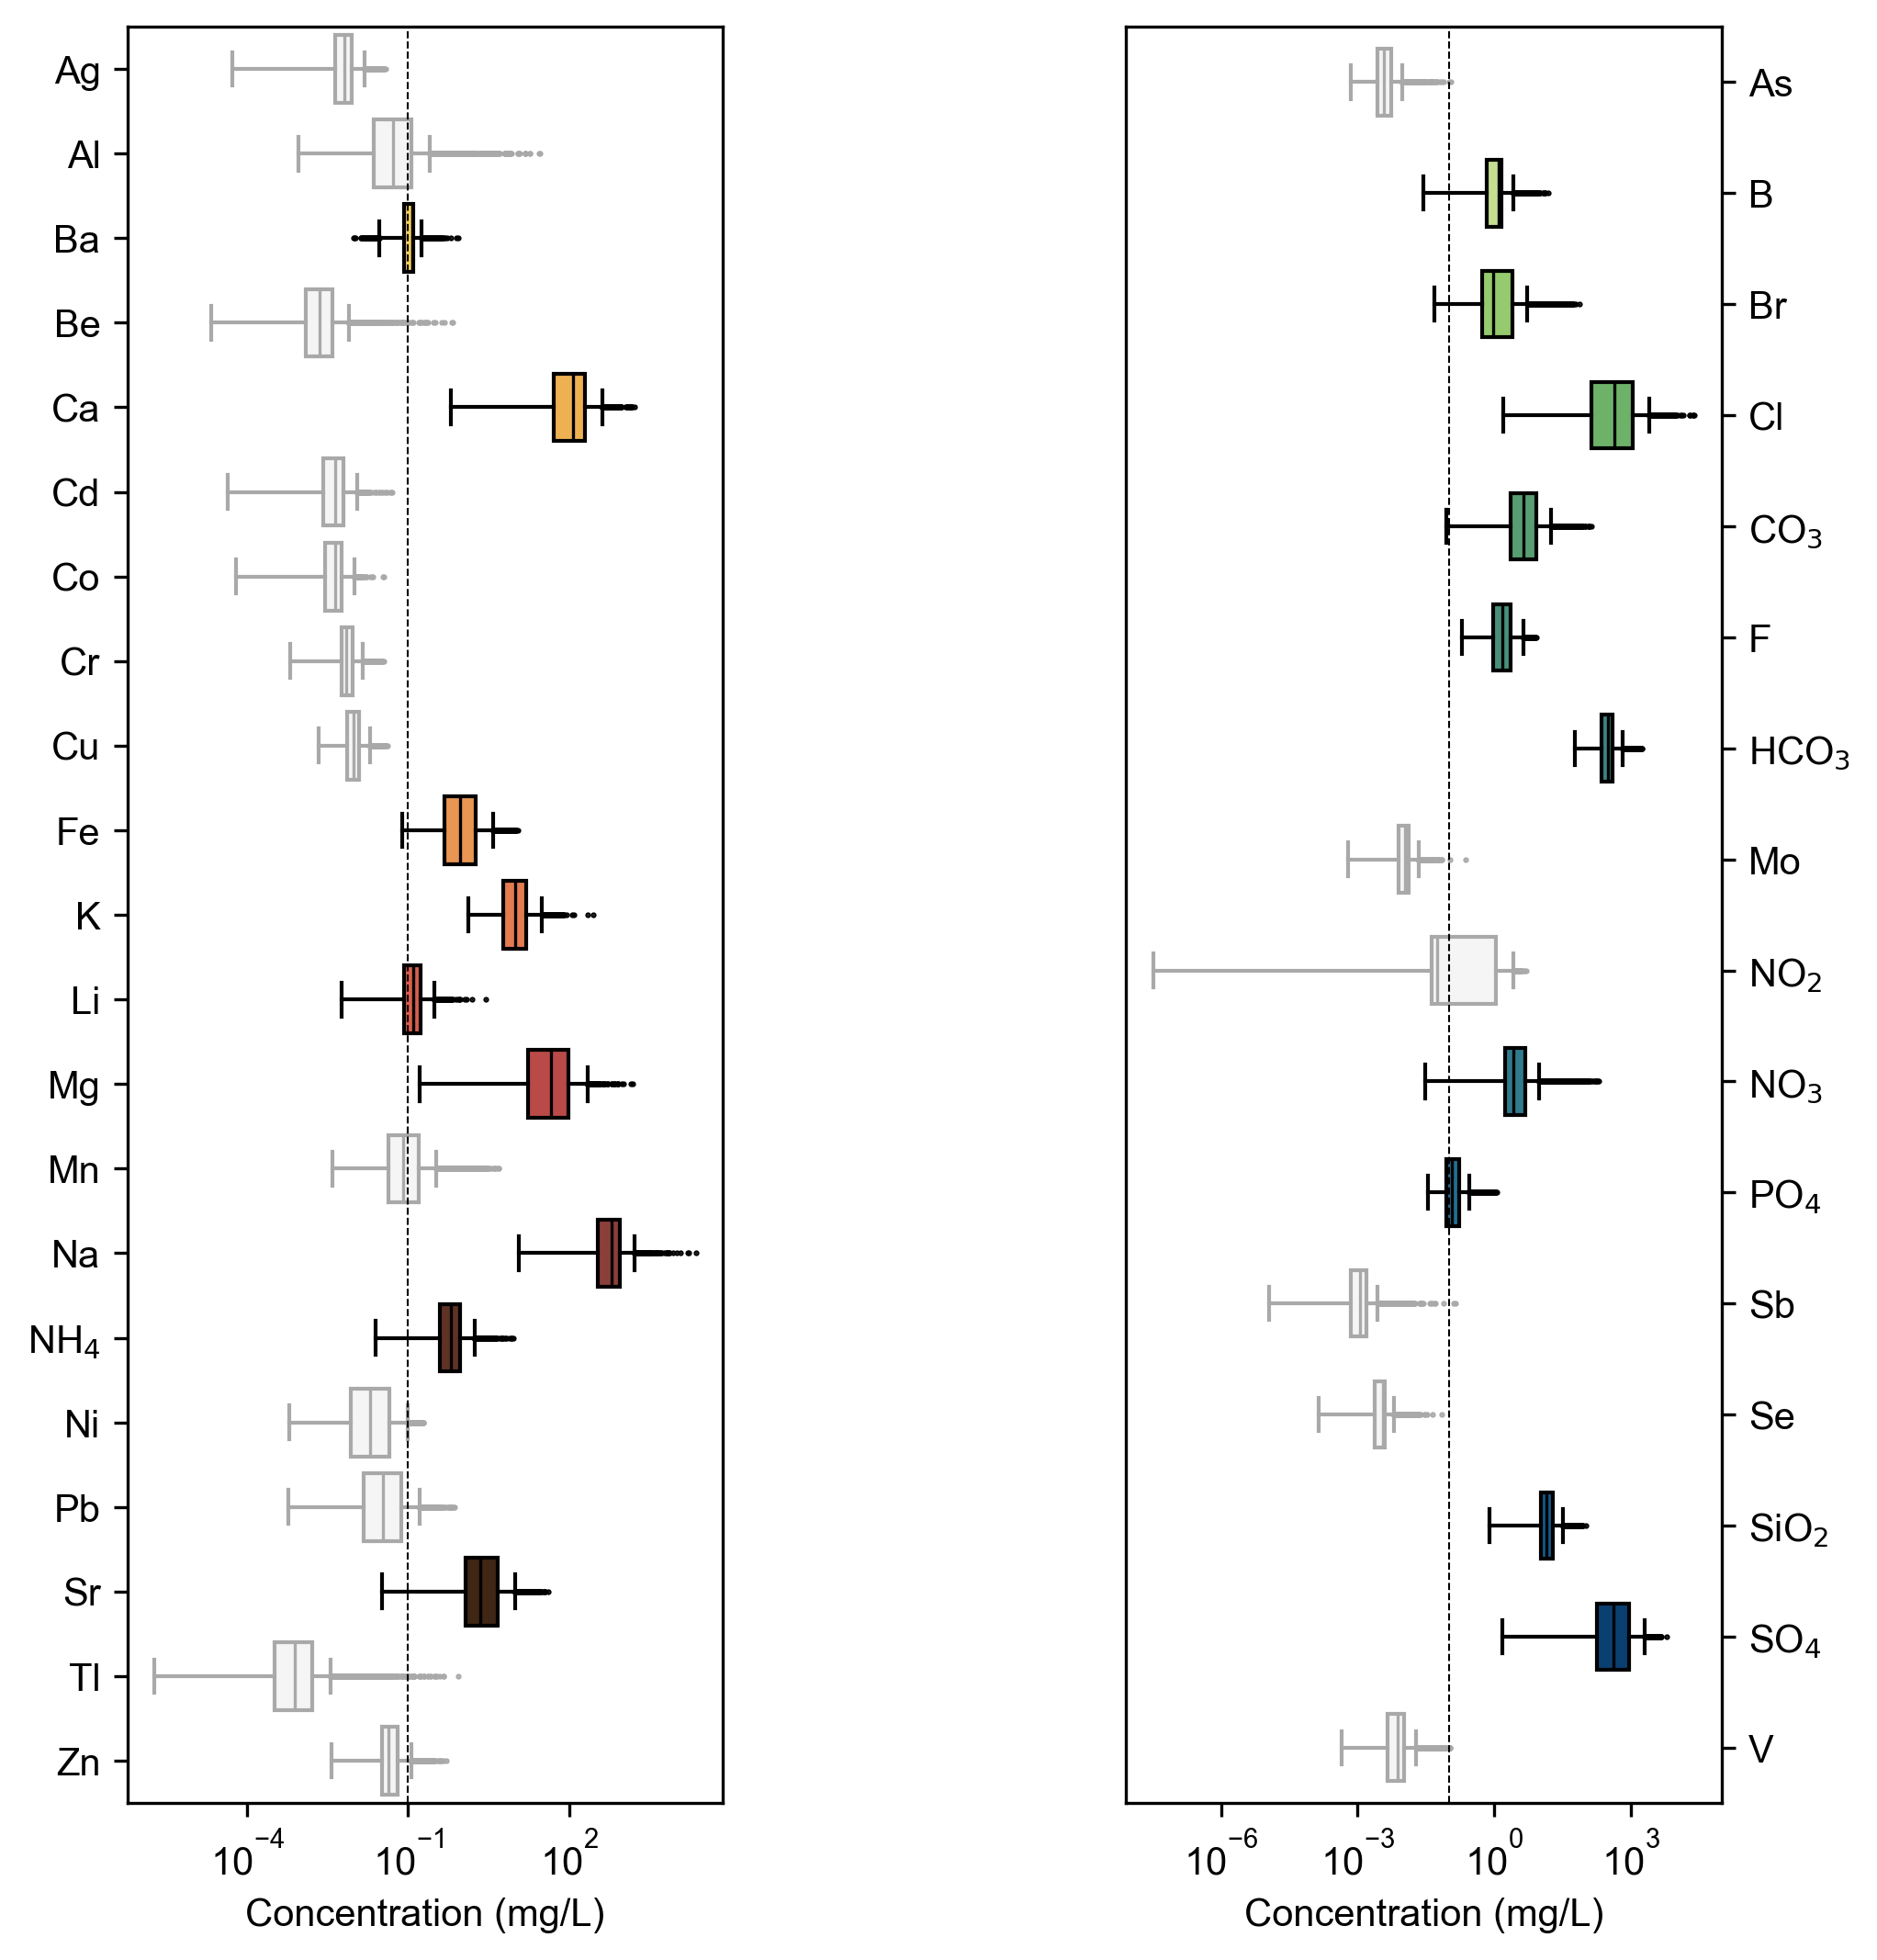

In [13]:
# figure - boxplot split by anions and cations
figsize = (6.7, 7)
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=figsize, sharex=False, width_ratios=[1,0.6,1],
                        layout='constrained')

# hide center column of axes (will add byproduct combinations in post-processing)
axs[1].axis('off')

# plot cation boxplots
cation_ax = axs[0]
cation_species = sorted([s for s in species_type_dict if species_type_dict[s] == 'cation'], key=str.lower, reverse=True)
cation_cols = [f'{s}_mgL_mean' for s in cation_species]
cation_bp = cation_ax.boxplot(
    [comp_df[col] for col in cation_cols],
    widths=0.8,
    vert=False,
    patch_artist=True,
    tick_labels=[subscript_numbers(s) for s in cation_species],
    flierprops=dict(markersize=0.5),
    medianprops=dict(color='black', linewidth=0.8)
)
for i, (patch, species) in enumerate(zip(cation_bp['boxes'], cation_species)):
    facecolor = species_color_dict[species]
    edgecolor = 'darkgrey' if facecolor in ('whitesmoke', 'lightgrey') else 'black'
    patch.set_facecolor(facecolor)
    patch.set_edgecolor(edgecolor)
    cation_bp['medians'][i].set_color(edgecolor)
    cation_bp['whiskers'][2*i].set_color(edgecolor)
    cation_bp['whiskers'][2*i + 1].set_color(edgecolor)
    cation_bp['caps'][2*i].set_color(edgecolor)
    cation_bp['caps'][2*i + 1].set_color(edgecolor)
    cation_bp['fliers'][i].set_markerfacecolor(edgecolor)
    cation_bp['fliers'][i].set_markeredgecolor(edgecolor)
cation_ax.set_xscale('log')

# plot anion boxplots
anion_ax = axs[2]
anion_species = sorted([s for s in species_type_dict if species_type_dict[s] == 'anion'], key=str.lower, reverse=True)
anion_cols = [f'{s}_mgL_mean' for s in anion_species]
anion_bp = anion_ax.boxplot(
    [comp_df[col] for col in anion_cols],
    widths=0.6,
    vert=False,
    patch_artist=True,
    tick_labels=[subscript_numbers(s) for s in anion_species],
    flierprops=dict(markersize=0.5),
    medianprops=dict(color='black', linewidth=0.8)
)
for i, (patch, species) in enumerate(zip(anion_bp['boxes'], anion_species)):
    facecolor = species_color_dict[species]
    edgecolor = 'darkgrey' if facecolor in ('whitesmoke', 'lightgrey') else 'black'
    patch.set_facecolor(facecolor)
    patch.set_edgecolor(edgecolor)
    anion_bp['medians'][i].set_color(edgecolor)
    anion_bp['whiskers'][2*i].set_color(edgecolor)
    anion_bp['whiskers'][2*i + 1].set_color(edgecolor)
    anion_bp['caps'][2*i].set_color(edgecolor)
    anion_bp['caps'][2*i + 1].set_color(edgecolor)
    anion_bp['fliers'][i].set_markerfacecolor(edgecolor)
    anion_bp['fliers'][i].set_markeredgecolor(edgecolor)
anion_ax.set_xscale('log')
anion_ax.yaxis.tick_right()

for ax in [cation_ax, anion_ax]:
    ax.axvline(x=conc_threshold, color='black', linestyle='--', linewidth=0.5)
anion_ax.set_xlabel('Concentration (mg/L)')
cation_ax.set_xlabel('Concentration (mg/L)')